# Run sorters and analyze them

Now that we've explored our data and have cleaned/preprocessed it, it's finally time to sort!

Let's read in our preprocessed recording

In [1]:
from pathlib import Path

import spikeinterface.full as si

si.set_global_job_kwargs(n_jobs=2)

In [2]:
# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "cnn_2026")

recording_name = 'dandiset-000939-90s'

data_folder = base_data_folder / "data"
result_folder = base_data_folder / "results" / recording_name

path_to_recording = data_folder / recording_name

preprocessed_path = result_folder / Path('preprocessed')
preprocessed_recording = si.load(preprocessed_path)

In [3]:
%matplotlib widget
si.plot_traces(preprocessed_recording, backend="ipywidgets")

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

### Check installation

We can now run spike sorting on the above recording. We will use different spike sorters for this demonstration, to show how easy `SpikeInterface` makes it easy to interchengably run different sorters :)

Let's first check the available and installed sorters in `SpikeInterface`.
We will sort the bandpass cached filtered recording the `recording_saved` object.

In [4]:
si.available_sorters()

['combinato',
 'dartsort',
 'hdsort',
 'herdingspikes',
 'ironclust',
 'kilosort',
 'kilosort2',
 'kilosort2_5',
 'kilosort3',
 'kilosort4',
 'lupin',
 'mountainsort4',
 'mountainsort5',
 'pykilosort',
 'rtsort',
 'simple',
 'spykingcircus',
 'spykingcircus2',
 'tridesclous',
 'tridesclous2',
 'vanillasort',
 'waveclus',
 'yass']

In [5]:
si.installed_sorters()

['lupin', 'simple', 'spykingcircus2', 'tridesclous2']

The `spikeinterface.sortingcomponents` module includes functions that can be used to create custom spike sorting pipelines built-in in `SpikeInterface`. We have used it to create some sorters

* `lupin` (developed by the SpikeInterface team - primarily Sam Garcia and Pierre Yger)
* `tridesclous2` (developed by Samuel Garcia)
* `spykingcircus2` (developed by Pierre Yger)
* `simple` which is only for demo and teaching

Let's run one now. Every sorter comes with a dizzying array of parameters, which we can check using `get_default_sorter_params`

In [6]:
si.get_default_sorter_params('lupin')

{'apply_preprocessing': True,
 'preprocessing_dict': None,
 'apply_motion_correction': False,
 'motion_correction_preset': 'dredge_fast',
 'clustering_ms_before': 0.3,
 'clustering_ms_after': 1.3,
 'whitening_radius_um': 100.0,
 'detection_radius_um': 50.0,
 'features_radius_um': 120.0,
 'split_radius_um': 60.0,
 'template_radius_um': 100.0,
 'merge_similarity_lag_ms': 0.5,
 'freq_min': 150.0,
 'freq_max': 7000.0,
 'cache_preprocessing_mode': 'auto',
 'peak_sign': 'neg',
 'detect_threshold': 5.0,
 'n_peaks_per_channel': 5000,
 'n_svd_components_per_channel': 5,
 'n_pca_features': 4,
 'clustering_recursive_depth': 3,
 'ms_before': 1.0,
 'ms_after': 2.5,
 'template_sparsify_threshold': 1.0,
 'template_min_snr_ptp': 4.0,
 'template_max_jitter_ms': 0.2,
 'template_matching_engine': 'wobble',
 'min_firing_rate': 0.1,
 'gather_mode': 'memory',
 'job_kwargs': {},
 'seed': None,
 'save_array': True,
 'debug': False}

### Run sorter installed locally

This run a sorter which is installed in the current python environements.

In [7]:
sorter_params = {'apply_motion_correction': False, 'apply_preprocessing': True}

In [8]:
sorting_lupin = si.run_sorter(
    sorter_name='lupin', 
    recording=preprocessed_recording,
    folder=result_folder / 'sorting_lupin',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)


                            .::----::..
                 ..:-+#%*+#%@@@@@@@+..:+#+.
                .+@%%@@@@@@@@@@@@@@#:  .=@=
                -@@@@@@@@@@@@@@@@@@%-. .=@*
                .@@@@@@@@@@@@@@@@@@@*. .-%#
                 %@@@@@@@@@@@@@@@@@@*.  :#%
                 =%%@@@@@@@@@@@@@@%%+:  .+@.
                 -%#@@@@@@@@@@@@@@%*==  .-@.
                 :#%@@@@@@@@@@@@@@%#+#  .=@.
                 .+%@@@@@@@@@@@@@@@%#@. .+@.
                 .+*#@@@@@@@@@@@@@@@%@. .+@:
                 .=%+@@@@@@@@@@@@@@@@*.  =%-.
                  :#%##@@@@@@@@@@@@%%-.  :%+.
               ..:=**%@@@@@@@@@@@@@@@:.  .%%......
             .+#@%%%@**@%@@@@@@@@@@@*....=%@%@@@@@%=..
            .*@@@@@@@@@@@=#@@@@@@@@@@*=:.:.#@@@@@@%%-.
           .-%%@@@@@@@@@@@@@#+%@+-::-+=:=::+@@@@@@##-.
           .:%@@@@@@@@@@@@@@@@@%+%##*%%%**%@@@@@@##+.
            .+@@@@@@@@@@@@@@@@#***++***@@@@@@@@%%%=.
             .:*@@@@@@@@%=-.....   ....:-*%%%%%+-.
                 ..:-:..
                       

write_memory (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

get protoype waveforms (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

detect peaks (matched_filtering) (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

detect_peaks(): 62091 peaks found
select_peaks(): 62091 peaks kept for clustering


... (4 outputs left out)

estimate_templates_with_accumulator (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

find spikes (wobble) (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

lupin run time 40.68s


/home/pierre/github/CNN_handson_2026/.venv/lib/python3.12/site-packages/spikeinterface/core/core_tools.py:988: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


In [9]:
sorting_lupin

NumpyFolder (NumpyFolderSorting): 111 units - 1 segments - 20.0kHz

## external sorter : kilosort4

SpikeInterface also supports external sorters such as `kilosort`, `dartsort` and `mountainsort`. But we leave it up to the user to install these. Luckily, there should be simple install instructions if you try and fail to run the sorter

In [10]:
si.get_default_sorter_params('kilosort4')

/home/pierre/github/CNN_handson_2026/.venv/lib/python3.12/site-packages/spikeinterface/sorters/external/kilosort4.py:112: UserWarning: Kilosort4 is not installed. Please install kilosort4 to get the parameters.
  warnings.warn("Kilosort4 is not installed. Please install kilosort4 to get the parameters.")


{'pool_engine': 'process',
 'n_jobs': 2,
 'chunk_duration': '1s',
 'progress_bar': True,
 'mp_context': None,
 'max_threads_per_worker': 1}

In [11]:
sorter_params = {
    "do_correction": False,
    "use_binary_file": False,
}

sorting_kilosort = si.run_sorter(
    sorter_name='kilosort4', 
    recording=preprocessed_recording,
    folder=result_folder / 'sorting_kilosort',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)

Exception: The sorter kilosort4 is not installed. Please install it with:

To use Kilosort4 run:

        >>> pip install kilosort --upgrade

    More information on Kilosort4 at:
        https://github.com/MouseLand/Kilosort
    

In [ ]:
si.get_default_sorter_params('dartsort')

In [24]:
sorter_params = {
    "do_motion_estimation": False,
}

sorting_dartsort = si.run_sorter(
    sorter_name='dartsort', 
    recording=preprocessed_recording,
    folder=result_folder / 'sorting_dartsort',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)

detect_bad_channels (workers: 2 processes fork):   0%|          | 0/100 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/100 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/dartsort/main.py:156: RuntimeWarning: Your (preprocessed) recording is not saved on disk in time-major format, so reading data could be slow. You could set the config flag copy_recording_to_tmpdir to keep it in a scratch folder while dartsort runs, or cache it long-term with its .save() method.
  check_recording(recording, copy_flag=copy_rec_flag)


Load initial denoiser fit data:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

Epochs:   0%|          | 0/100 [00:00<?, ?epoch/s]

Load examples for denoiser fitting:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

... (36 outputs left out)

Raw templates:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

Templates:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

dartsort run time 758.71s


/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/core_tools.py:988: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


# The `sorting` object 

In [25]:
sorting_lupin

NumpyFolder (NumpyFolderSorting): 110 units - 1 segments - 20.0kHz

As we'll see, the main output of a `SpikeInterface` pipeline is the `SortingAnalyzer` object, which you'll be able to do _lots_ of fun stuff with. But there are some simple things you can do with the `Sorting` object.

## Get spike trains

In [26]:
# spike times in frame

unit_id = sorting_lupin.unit_ids[0]

spike_times = sorting_lupin.get_unit_spike_train(unit_id)
print(spike_times)

# spike times in seconds
spike_times = sorting_lupin.get_unit_spike_train(unit_id, return_times=True)
print(spike_times)


[  11500   11945   13351   16176   18913   21011   21431   21699   22497
   23225   23317   23473   23525   24834   25179   25931   28432   36358
   46451   70944   88711  104861  107263  114728  114822  116269  116312
  118031  118642  119830  120191  121004  122590  126073  126183  126538
  155658  159029  183798  190195  207125  207349  208036  234819  241286
  241458  256826  262459  262930  267215  285663  322523  328635  330039
  344374  366097  366145  372589  379908  381518  389504  392328  396472
  397608  401868  405350  407053  416263  447498  449086  467935  504262
  507244  515438  538823  541444  542123  542425  572368  576637  588229
  588404  608441  616618  617525  634800  639726  639990  645683  657225
  658039  680667  711099  725114  745437  750567  764421  770501  789173
  844080  844138  858333  859309  881849  882256  884603  895992  898471
  905275  909536  912419  912976  913007  913130  916236  916529  919041
  919458  919709  921684  922114  932272  933172  9

In [27]:
# time slice
sorting_lupin.frame_slice(0, 30_000)

FrameSliceSorting: 110 units - 1 segments - 20.0kHz

## Plot

In [28]:
si.plot_rasters(sorting_lupin, unit_ids=sorting_lupin.unit_ids[:60], time_range=(0, 5), backend='ipywidgets')

AppLayout(children=(VBox(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='…

## Compare sorter outputs

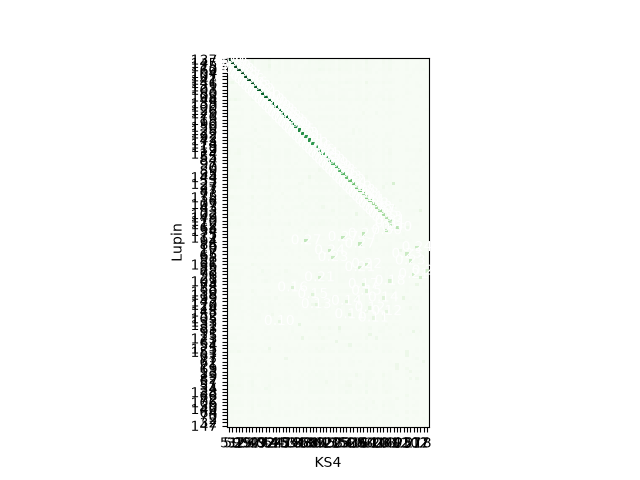

In [29]:
comp = si.compare_two_sorters(sorting_lupin, sorting_kilosort, 'Lupin', 'KS4')
w = si.plot_agreement_matrix(comp)
import pylab as plt
plt.show()

# Analyze Sorting

We now have a sorter and recording. Great! Now we can get on to the fun stuff: what shape are our unit templates? Which units are correlated with each other? Where on the probe are the units? This require computing extra information. In `SpikeInterface` we do this by creating an object called a `SortingAnalyzer`. 

A `SortingAnalyzer` combines a recording with a sorting in a unified way, no matter which sorter or recording format you used. Once you have an analyzer, you can compute postprocessing _extensions_ (like spike locations, waveforms, template metrics, ...) in exactly the same way for every sorter. They can also be used to keep track of curation, merging and splitting, and more.

This unified framework has several benefits. The main one is that the analyzer defines a sorter-agnostic format for post-sorting analysis. Hence:
- You can compare sorters on a level playing field (i.e. all the extensions are computed in the same way, for all sorters)
- Your postprocessing pipeline can be identical, whether using mountainsort to sort tetrode data or kilosort to sort NeuroPixel data, creating a unified pipeline in your lab.
- External tools have a simple starting point to work from. This should make tooling in the community easier, and there are already several examples of this:
  - NeuronConv contains a `SortingAnalyzerToNWB` function
  - spikeinterface-gui, sortingview and UnitMatch can take an analyzer as their initial input.
  - UnitRefine
  - BombCell
  - IBL viewer tools

Hopefully you're now convinced that creating a `SortingAnalyzer` will make your life easier, and smooth the path to using new tools in your analysis pipeline. So, let's make one.

When you make the analyzer, you can either make in _in memory_ or _in folder_. 

In [30]:
analyzer_in_memory = si.create_sorting_analyzer(
    sorting=sorting_lupin,
    recording=preprocessed_recording, 
)

analyzer_in_folder = si.create_sorting_analyzer(
    sorting=sorting_lupin, 
    recording=preprocessed_recording, 
    folder=result_folder / f"analyzer_lupin",
    overwrite=True,
    format="binary_folder",
)

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/basesorting.py:646: UserWarning: The recording registered to this sorting object will not be saved to disk. Reloading the sorting later will not include the recording
  warnings.warn(


When in memory, the analyzer is stored in RAM. This makes computation faster, but will use more RAM. You can save your `analyzer_in_memory` to a folder at any point using `analyzer_in_memory.save_as` (more info in [Postprocessing docs](https://spikeinterface.readthedocs.io/en/stable/modules/postprocessing.html)). For this demo, we'll use a folder based analyzer. Go take a look in the folder. You'll see that it contains recording information, sorting information and more!

# Extensions

Each thing-you'd-like-to-compute is stored as an Extention of the analyzer. Let's compute the templates: the averaged waveforms from all (or a large random sample of) individual spikes.

In [32]:
analyzer_in_folder.compute("templates")

AssertionError: Extension templates requires random_spikes|waveforms to be computed first

Oh no - an error! This is due to the fact that extensions depend on each other. For example, you can't compute template similarity (how similar unit templates are to one another) without computing templates. The full dependency graph can be seen here:

![image](images/parent_child.svg)

So, when we compute extensions we need to know which _other_ extensions we need to compute beforehand... Let's compute a few. You can either compute one at a time, or give the `analyzer` a big dictionary of extensions (recommended! It will do some smart stuff to save some computation time):

In [33]:
# just one
analyzer_in_folder.compute("random_spikes", max_spikes_per_unit=1000)

# or lots: here we also specify some kwargs
analyzer_in_folder.compute({
    "templates": {},
    "waveforms": {},
    "correlograms": {},
    "noise_levels": {'method': 'std'},
    "spike_amplitudes": {},
    "spike_locations": {},
    "template_metrics": {'include_multi_channel_metrics': True},
    "unit_locations": {},
    "template_similarity": {'method': 'l1'},
    "quality_metrics": {},
})


compute_waveforms (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/metrics/template/template_metrics.py:301: UserWarning: With less than 10 channels, multi-channel metrics might not be reliable.
  warnings.warn(


Compute : spike_amplitudes + spike_locations (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/…

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/analyzer_extension_core.py:1204: UserWarning: The following metrics will not be computed due to missing dependencies: ['nearest_neighbor', 'mahalanobis', 'silhouette', 'd_prime']
  warnings.warn(
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in divi

In [34]:
analyzer_in_folder

SortingAnalyzer: 60 channels - 110 units - 1 segments - binary_folder - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, correlograms, noise_levels, template_metrics, unit_locations, template_similarity, spike_amplitudes, spike_locations, quality_metrics

To see which extensions are available to compute, use `analyzer_in_folder.get_computable_extensions()`. A good way to see which arguments an extension accepts, you can use e.g. `analyzer_in_folder.get_default_extension_params('template_metrics')`

Now take another look in your analyzer folder. You'll find lots of new folders containing your extensions! You can load this data directly, but `SpikeInterface` contains a lot of handy loader functions. The notation is always `analyzer.get_extension("extension_name").get_data()`. Let's look at the quality metrics. These are measures of how _good_ a unit is (more details: https://spikeinterface.readthedocs.io/en/latest/modules/qualitymetrics.html) Note that which quality metrics are computed depends on which other extensions you've computed.

In [35]:
quality_metrics = analyzer_in_folder.get_extension("quality_metrics").get_data()
quality_metrics

,num_spikes,firing_rate,presence_ratio,snr,isi_violations_ratio,isi_violations_count,rp_contamination,rp_violations,sliding_rp_violation,sync_spike_2,...,amplitude_cv_median,amplitude_cv_range,amplitude_cutoff,noise_cutoff,noise_ratio,amplitude_median,drift_ptp,drift_std,drift_mad,sd_ratio
0,419,4.655556,1.0,4.833174,0.683523,4,1.000000,2,NaN,0.066826,...,NaN,NaN,NaN,2.477007,0.214286,-105.300003,NaN,NaN,NaN,1.804225
2,554,6.155556,1.0,3.560611,0.488733,5,0.356945,2,NaN,0.074007,...,0.311484,0.112450,0.000000,-0.031169,0.062500,-78.292496,NaN,NaN,NaN,1.116757
10,918,10.200000,1.0,3.962799,0.284791,8,0.317345,5,NaN,0.063181,...,0.292780,0.096509,0.010776,0.302787,0.164502,-79.072495,NaN,NaN,NaN,1.129629
13,584,6.488889,1.0,4.058064,0.527773,6,1.000000,6,NaN,0.065068,...,0.260887,0.130600,0.000000,-0.200151,0.083736,-78.584999,NaN,NaN,NaN,1.113606
14,732,8.133333,1.0,4.133907,1.063782,19,1.000000,10,NaN,0.083333,...,0.264699,0.122009,0.000000,0.256079,0.137931,-83.070000,NaN,NaN,NaN,1.178110
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,260,2.888889,1.0,3.881725,0.443787,1,1.000000,1,NaN,0.103846,...,NaN,NaN,NaN,0.676731,0.087912,-139.229996,NaN,NaN,NaN,1.940075
148,489,5.433333,1.0,3.958949,0.501838,4,0.502765,2,NaN,0.118609,...,NaN,NaN,NaN,0.302851,0.086667,-94.964996,NaN,NaN,NaN,1.404232
149,205,2.277778,1.0,4.262479,0.000000,0,0.000000,0,NaN,0.078049,...,NaN,NaN,NaN,0.321970,0.112299,-103.154999,NaN,NaN,NaN,1.131991
150,805,8.944444,1.0,3.960597,0.000000,0,0.000000,0,0.055,0.055901,...,0.312254,0.212415,0.000000,0.223693,0.088889,-96.720001,NaN,NaN,NaN,1.220899


This is a `pandas` dataframe with information about each unit. Nice.

We can get the "raw" extension data from any other extensions too

In [36]:
template_similarity_data = analyzer_in_folder.get_extension("template_similarity").get_data()
template_similarity_data

array([[1.        , 0.5705787 , 0.11048579, ..., 0.        , 0.        ,
        0.29961962],
       [0.5705787 , 1.        , 0.18497634, ..., 0.        , 0.        ,
        0.40292025],
       [0.11048579, 0.18497634, 1.        , ..., 0.        , 0.        ,
        0.23004693],
       ...,
       [0.        , 0.        , 0.        , ..., 1.        , 0.11070496,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.11070496, 1.        ,
        0.        ],
       [0.29961962, 0.40292025, 0.23004693, ..., 0.        , 0.        ,
        1.        ]], shape=(110, 110), dtype=float32)

`SpikeInterface` also supports lots of plotting functions that are related to extensions (see more: https://spikeinterface.readthedocs.io/en/latest/modules/widgets.html#available-plotting-functions). Let's plot the spike locations, then a summary plot.

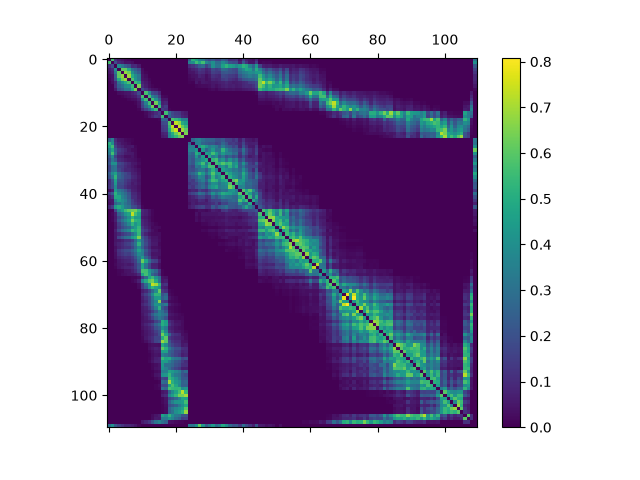

In [37]:
si.plot_template_similarity(analyzer_in_folder)

In [38]:
%matplotlib widget
si.plot_amplitudes(analyzer_in_folder, backend="ipywidgets")

AppLayout(children=(VBox(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='…

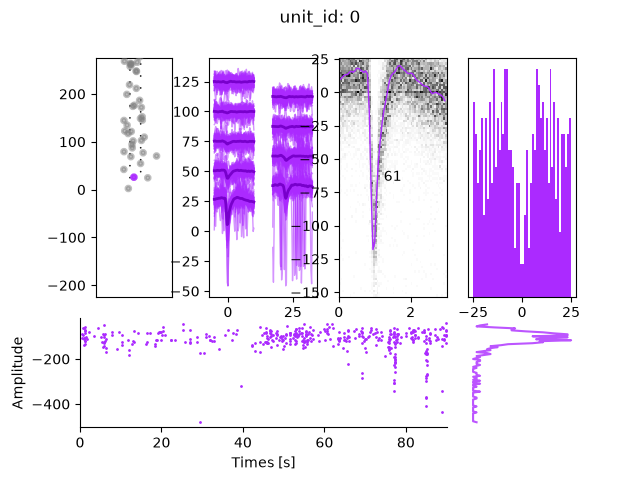

In [39]:
si.plot_unit_summary(analyzer_in_folder, unit_id=unit_id)
plt.show()

In [40]:
si.plot_quality_metrics(analyzer_in_folder, backend="ipywidgets")

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/widgets/metrics.py:66: UserWarning: Skipping ['drift_ptp', 'drift_std', 'drift_mad'] because they contain all NaNs
  warnings.warn(f"Skipping {nan_metrics} because they contain all NaNs")


AppLayout(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='center')), Sele…

# Export

We are trying to improve `export` options for the `SortingAnalyzer` so that SpikeInterface works with other tools. For example, we recently introduced the ability to `export_to_pynapple` (https://pynapple.org/)

In [41]:
spikes = si.to_pynapple_tsgroup(analyzer_in_folder)
spikes

Index    rate      x       y       z      num_spikes    firing_rate    presence_ratio    ...
-------  --------  ------  ------  -----  ------------  -------------  ----------------  -----
0        4.65564   8.35    25.96   1.0    419           4.66           1.0               ...
2        6.15566   -12.75  42.14   1.0    554           6.16           1.0               ...
10       10.20018  -12.48  144.53  1.0    918           10.2           1.0               ...
13       6.489     20.26   186.65  17.28  584           6.49           1.0               ...
14       8.13347   -6.5    199.08  14.39  732           8.13           1.0               ...
15       5.06675   13.36   211.66  16.66  456           5.07           1.0               ...
16       12.40021  -0.87   219.19  12.96  1116          12.4           1.0               ...
...      ...       ...     ...     ...    ...           ...            ...               ...
145      36.34507  32.28   804.94  1.73   3271          36.34       

If you want to know more about Pynapple, and use it to study the head direction cells in this dataset, there's a whole chapter about it on the [Open Software Summer School course](https://neuroinformatics.dev/course_ephys_osss/pynapple.html).

Another export option is `export_report`. This creates a cute little report about all your units:

In [ ]:
si.export_report(analyzer_in_folder, output_folder=result_folder / "lupin_report")